# 15 · Gene-regulatory networks along the alveolar lineage (pySCENIC)

**SCENIC** (Aibar *et al.* 2017) infers *regulons* - a transcription factor
(TF) plus the target genes that are both co-expressed with it (GRNBoost2) and
carry its DNA-binding motif near their TSS (cisTarget). Per-cell regulon
activity is scored with AUCell. It complements the CollecTRI TF activities of
Notebook 08, which use *prior-knowledge* regulons: agreement between the two
is evidence that a TF programme is genuinely active.

GRNBoost2 is stochastic, so pySCENIC was run three times on the Linux
workstation with different seeds; only TFs recovered in ≥2/3 runs, with
targets supported in ≥2/3 runs, are analysed ("consensus regulons").

Analyses
1. regulon specificity score (RSS; Suo *et al.* 2018) per cell type;
2. regulons associated with the aberrant basaloid fate (CellRank, Notebook 09);
3. concordance with CollecTRI activities computed from the paired
   aberrant-basaloid pseudobulk contrast (Notebook 09).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from adjustText import adjust_text
from scipy.spatial.distance import jensenshannon
from scipy.stats import spearmanr

from ipfatlas import enrichment, pseudobulk
from ipfatlas.config import setup
from ipfatlas.plotting import figsize, save_figure, set_style
from ipfatlas.utils import write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "15_scenic"
TAB = P.tables / "15_scenic"
SC = P.root / "data" / "linux_results" / "results_to_return" / "scenic" / "consensus"
assert SC.exists(), f"SCENIC results not found in {SC} (see linux_upstream/README.md)"

rec = pd.read_csv(SC / "regulon_recovery.tsv", sep="\t")
edges = pd.read_csv(SC / "consensus_regulons.tsv", sep="\t")
auc = pd.read_csv(SC / "auc_consensus.tsv.gz", sep="\t", index_col=0)
traj = sc.read_h5ad(P.processed / "epithelial_trajectory.h5ad")
cells = auc.index.intersection(traj.obs_names)
auc = auc.loc[cells]
obs = traj.obs.loc[cells]
colors = dict(zip(traj.obs["cell_type"].cat.categories, traj.uns["cell_type_colors"]))
print(f"{rec['robust'].sum()} robust regulons of {len(rec)} TFs found in any run; "
      f"{len(edges):,} consensus TF-target edges; AUCell for {len(cells):,} cells")
write_table(rec, TAB / "regulon_recovery", index=False)

310 robust regulons of 476 TFs found in any run; 19,050 consensus TF-target edges; AUCell for 5,892 cells


WindowsPath('J:/Portfolio_projects/Projects/scRNA/results/tables/15_scenic/regulon_recovery.csv')

## 1. Regulon specificity per cell type
RSS = 1 − Jensen–Shannon distance between the regulon's AUC distribution
(normalised to sum 1 over cells) and a cell-type indicator vector; 1 means the
regulon is active only in that cell type.

J:\Portfolio_projects\Projects\scRNA\.cache\tmp\ipykernel_24420\3378757356.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_auc = auc[top].groupby(labels.values).mean()


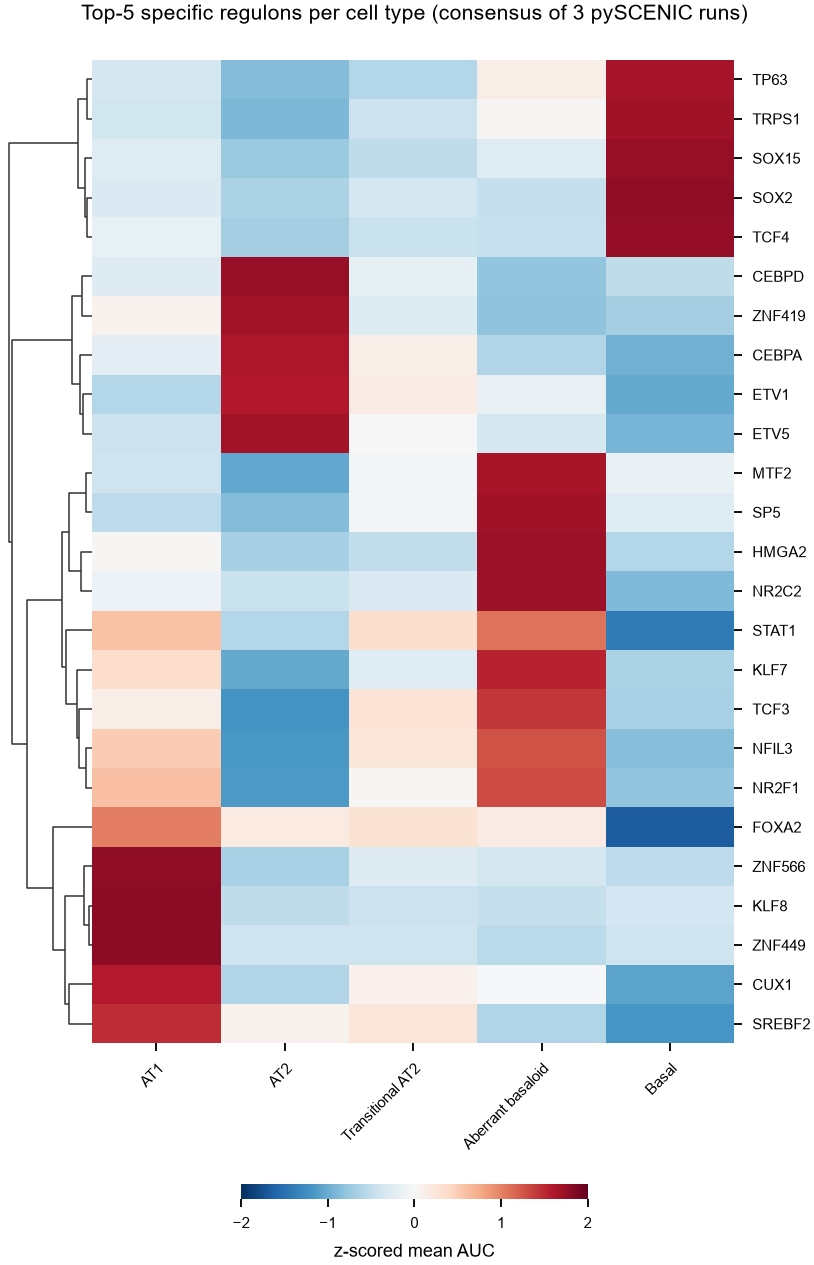

In [2]:
def rss(auc: pd.DataFrame, labels: pd.Series) -> pd.DataFrame:
    a = auc.div(auc.sum(axis=0).replace(0, np.nan), axis=1).fillna(0)
    out = {}
    for ct in labels.cat.categories:
        ind = (labels == ct).to_numpy().astype(float)
        ind /= ind.sum()
        out[ct] = {r: 1 - jensenshannon(a[r].to_numpy(), ind, base=2) for r in a.columns}
    return pd.DataFrame(out)


labels = obs["cell_type"].cat.remove_unused_categories()
R = rss(auc, labels)
write_table(R.round(4), TAB / "regulon_specificity_scores")
top = sorted({r for ct in R.columns for r in R[ct].nlargest(5).index})

mean_auc = auc[top].groupby(labels.values).mean()
z = (mean_auc - mean_auc.mean()) / mean_auc.std()
g = sns.clustermap(z.T, cmap="RdBu_r", center=0, vmin=-2, vmax=2, col_cluster=False, figsize=(100 / 25.4, 140 / 25.4),
                   cbar_kws={"label": "z-scored mean AUC", "orientation": "horizontal"},
                   cbar_pos=(0.3, 0.025, 0.4, 0.012),  # under the cell-type labels, clear of the dendrogram
                   dendrogram_ratio=(0.12, 0.02), yticklabels=True, xticklabels=True)
g.ax_heatmap.tick_params(labelsize=5)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
g.ax_heatmap.set_xlabel("")
g.ax_cbar.tick_params(labelsize=5)
g.ax_cbar.xaxis.label.set_size(6)
g.ax_cbar.set_position((0.3, 0.025, 0.4, 0.012))  # any later subplots_adjust would move it back
g.fig.suptitle("Top-5 specific regulons per cell type (consensus of 3 pySCENIC runs)", y=1.01, fontsize=7)
save_figure(g.fig, "S15_regulon_specificity_heatmap", FIG)
plt.show()

**Result.** 310 of the 476 TFs found in any run were recovered in at least two of
the three runs, with 19,050 consensus TF–target edges and AUCell scores for 5,892
alveolar lineage cells. The most specific regulons are known lineage regulators:
SOX2, TP63 and SOX15 in basal cells, and ETV5, CEBPA and CEBPD in AT2 cells.
Aberrant basaloid cells are marked by SP5, HMGA2, NR2C2, MTF2 and KLF7. Transitional
AT2 cells have no regulon of their own (highest RSS 0.13, against 0.29–0.58 in the
other four types): their regulon activity is shared with neighbouring states, as
expected for an intermediate state.

## 2. Regulons associated with commitment to the aberrant basaloid fate
Spearman correlation between regulon AUC and CellRank fate probability
towards aberrant basaloid cells, within AT2 + transitional AT2 cells (the
uncommitted pool where a fate bias would act).

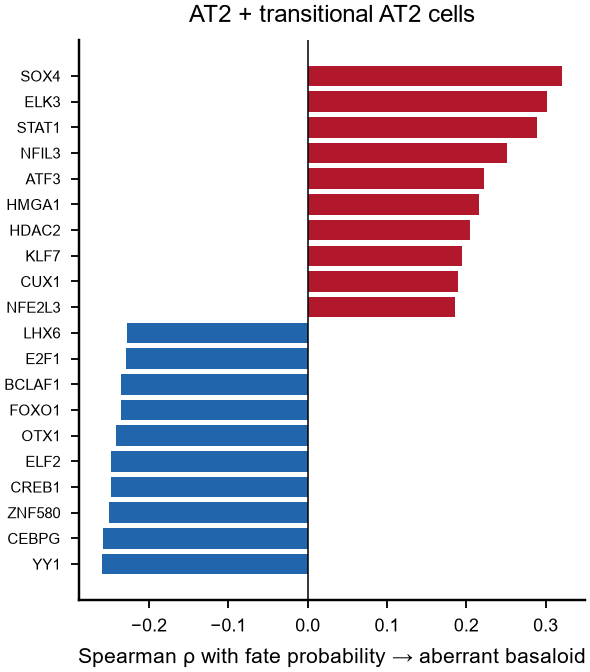

In [3]:
pool = obs["cell_type"].isin(["AT2", "Transitional AT2"]).to_numpy()
fate = obs.loc[pool, "fate_Aberrant basaloid"]
cor = pd.DataFrame([(r, *spearmanr(auc.loc[pool, r], fate)) for r in auc.columns],
                   columns=["regulon", "rho", "P"]).set_index("regulon")
from statsmodels.stats.multitest import multipletests  # noqa: E402

cor["FDR"] = multipletests(cor["P"], method="fdr_bh")[1]
cor = cor.sort_values("rho")
write_table(cor.round(5), TAB / "regulon_vs_basaloid_fate")

show = pd.concat([cor.head(10), cor.tail(10)])
fig, ax = plt.subplots(figsize=figsize(75, 85))
ax.barh(range(len(show)), show["rho"], color=np.where(show["rho"] > 0, "#B2182B", "#2166AC"))
ax.set_yticks(range(len(show)), show.index, fontsize=5)
ax.axvline(0, lw=0.5, color="black")
ax.set_xlabel("Spearman ρ with fate probability → aberrant basaloid")
ax.set_title("AT2 + transitional AT2 cells")
save_figure(fig, "Fig4_regulons_basaloid_fate", FIG)
plt.show()

### Regulon activity along the path towards aberrant basaloid cells

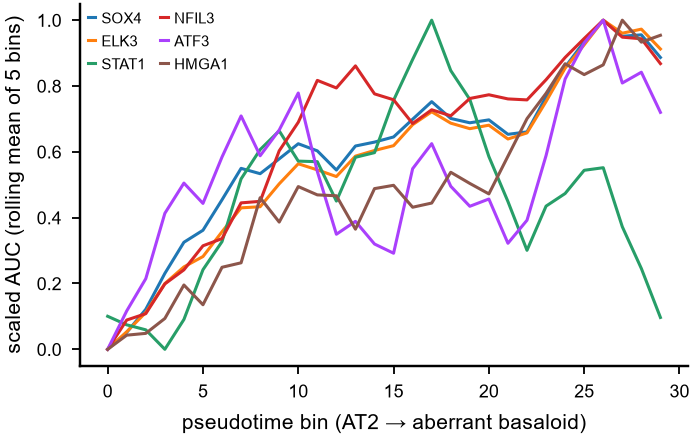

In [4]:
lead = list(cor.tail(6).index[::-1])
path = obs["cell_type"].isin(["AT2", "Transitional AT2", "Aberrant basaloid"]) & (
    obs["fate_Aberrant basaloid"] >= obs["fate_AT1"])
bins = pd.qcut(obs.loc[path, "dpt_pseudotime"].rank(method="first"), 30, labels=False)
tr = auc.loc[path[path].index, lead].groupby(bins.values).mean()
tr = tr.rolling(5, center=True, min_periods=3).mean()  # single bins hold ~20-60 cells and are noisy
fig, ax = plt.subplots(figsize=figsize(90, 55))
for r in lead:
    ax.plot(tr.index, (tr[r] - tr[r].min()) / (tr[r].max() - tr[r].min()), lw=1, label=r)
ax.set_xlabel("pseudotime bin (AT2 → aberrant basaloid)")
ax.set_ylabel("scaled AUC (rolling mean of 5 bins)")
ax.legend(fontsize=5, ncol=2)
save_figure(fig, "S15_regulon_trends_pseudotime", FIG)
plt.show()

**Result.** Within AT2 and transitional AT2 cells, 225 of the 310 regulons correlate
with the aberrant basaloid fate probability at FDR < 0.05, but with thousands of
cells even weak correlations are significant: only 25 have |ρ| > 0.2. The strongest
positive regulons are SOX4 (ρ = 0.32), ELK3 (0.30), STAT1 (0.29), NFIL3 (0.25),
ATF3 (0.22) and HMGA1 (0.22). *SOX4* is also one of the genes most correlated with
the fate in Notebook 09, so expression and regulon activity agree on it. Along
pseudotime, the activity of these regulons rises from AT2 cells towards the aberrant
basaloid end of the path.

## 3. Concordance with prior-knowledge TF activities (CollecTRI)
CollecTRI activities are inferred from the paired pseudobulk contrast
aberrant basaloid vs other alveolar epithelium (Notebook 09) and compared with
the SCENIC regulon difference between the same groups (mean AUC difference).

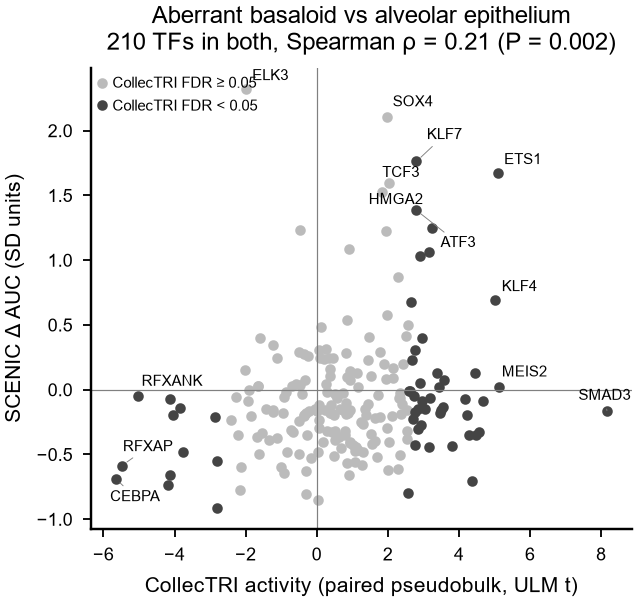

,scenic_delta_auc_sd,collectri_activity,collectri_padj
ELK3,2.321,-1.982,0.142
SOX4,2.103,1.970,0.145
KLF7,1.761,2.804,0.030
ETS1,1.673,5.090,0.000
TCF3,1.591,2.027,0.133
HMGA2,1.522,1.829,0.181
ATF3,1.389,2.781,0.030
STAT1,1.246,3.252,0.010
NFIL3,1.233,-0.473,0.779
NR2C2,1.223,1.952,0.149


In [5]:
pair = pd.read_csv(P.tables / "09_trajectory" / "aberrant_basaloid_vs_alveolar_paired_edgeR.csv")
stat = pseudobulk.stat_matrix(pair, "stat")
tf_act, tf_padj = enrichment.activity_from_stats(stat, enrichment.resource("collectri"))
tf_act = tf_act.iloc[0]
is_bas = (obs["cell_type"] == "Aberrant basaloid").to_numpy()
ref = obs["cell_type"].isin(["AT2", "Transitional AT2", "AT1", "Basal"]).to_numpy()
d_auc = (auc[is_bas].mean() - auc[ref].mean()) / auc.std()
both = d_auc.index.intersection(tf_act.index)
cmp = pd.DataFrame({"scenic_delta_auc_sd": d_auc[both], "collectri_activity": tf_act[both],
                    "collectri_padj": tf_padj.iloc[0][both]})
rho, p = spearmanr(cmp["scenic_delta_auc_sd"], cmp["collectri_activity"])
write_table(cmp.round(4), TAB / "scenic_vs_collectri", index=True)

fig, ax = plt.subplots(figsize=figsize(80, 70))
sig = cmp["collectri_padj"] < 0.05
ax.scatter(cmp.loc[~sig, "collectri_activity"], cmp.loc[~sig, "scenic_delta_auc_sd"], s=6, color="#BBBBBB",
           label="CollecTRI FDR ≥ 0.05")
ax.scatter(cmp.loc[sig, "collectri_activity"], cmp.loc[sig, "scenic_delta_auc_sd"], s=6, color="#444444",
           label="CollecTRI FDR < 0.05")
lab = sorted(set(cmp["collectri_activity"].abs().nlargest(7).index)
             | set(cmp["scenic_delta_auc_sd"].abs().nlargest(7).index))
texts = [ax.text(cmp.loc[t, "collectri_activity"], cmp.loc[t, "scenic_delta_auc_sd"], t, fontsize=5) for t in lab]
adjust_text(texts, x=cmp["collectri_activity"].to_numpy(), y=cmp["scenic_delta_auc_sd"].to_numpy(), ax=ax,
            expand=(1.3, 1.8), arrowprops={"arrowstyle": "-", "lw": 0.3, "color": "grey"})
ax.legend(fontsize=5, loc="upper left", frameon=False)
ax.axhline(0, lw=0.4, color="grey")
ax.axvline(0, lw=0.4, color="grey")
ax.set_xlabel("CollecTRI activity (paired pseudobulk, ULM t)")
ax.set_ylabel("SCENIC Δ AUC (SD units)")
ax.set_title(f"Aberrant basaloid vs alveolar epithelium\n{len(both)} TFs in both, Spearman ρ = {rho:.2f} (P = {p:.1g})")
save_figure(fig, "S15_scenic_vs_collectri", FIG)
plt.show()
cmp.sort_values("scenic_delta_auc_sd", ascending=False).head(15).round(3)

**Result.** Over the 210 TFs with both a SCENIC and a CollecTRI regulon, the two
estimates agree only modestly (Spearman ρ = 0.21, P = 0.002). Agreement is better
where CollecTRI is confident: of the 55 TFs with CollecTRI FDR < 0.05, 16 also
differ by more than 0.5 SD in SCENIC, and 14 of these have the same sign: ETS1,
KLF4, KLF7, ATF3 and STAT1 are more active in aberrant basaloid cells, CEBPA and
NR3C1 less. The largest disagreement is SMAD3 (CollecTRI t = 8.2, SCENIC ≈ 0). SMAD3
is activated by phosphorylation downstream of TGF-β, so its targets can change
without its own mRNA following, and SCENIC, which needs a TF to be co-expressed with
its targets, cannot detect that. The two methods answer different questions
(co-expression networks inferred from these cells vs curated targets), so only TFs
supported by both are reported as active in aberrant basaloid cells.

## Summary

| question | result |
|---|---|
| robust regulons (≥ 2 of 3 runs) | 310 of 476 TFs; 19,050 TF–target edges |
| most specific regulons | basal SOX2, TP63; AT2 ETV5, CEBPA; aberrant basaloid SP5, HMGA2; none specific to transitional AT2 |
| regulons with the aberrant basaloid fate | SOX4 (ρ = 0.32), ELK3, STAT1, NFIL3, ATF3 |
| agreement with CollecTRI | ρ = 0.21 over 210 TFs; ETS1, KLF4, KLF7, ATF3, STAT1 up and CEBPA, NR3C1 down in both |